# Quantum-assisted deployment of mobile medical teams (Qiskit Fall Fest 2026)

**Domain:** Disaster Response. **Question:** a disaster hit 10 locations; 3 interchangeable mobile medical teams start from one depot.
Which 3 locations should receive a team, trading off patients, outbreak risk and travel time?

Run from the repository root (`jupyter nbconvert --to notebook --execute notebooks/experimentation.ipynb`).
Everything here uses **synthetic** data and the code in `src/`. Runtime: about 1 minute.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.problem import default_problem
from src.objective import make_formulation, objective_breakdown
from src.classical_solver import solve_exact
from src.quantum_model import (build_qubo, qubo_to_ising, ising_to_operator, default_penalty, exact_min_penalty,
                               verify_model_consistency, build_qaoa_circuit)
from src.qaoa_solver import QaoaConfig, run_qaoa, decode_counts
from src.evaluation import evaluate_run, random_baseline
problem = default_problem()

## 1. Input data (SYNTHETIC)
Travel time = distance / 0.5 km/min, so coordinates and travel times agree by construction.

In [2]:
problem.table()

,location,qubit,patients,travel_min,outbreak_risk,x_km,y_km
0,L1,0,80.0,20.0,90.0,9.85,1.74
1,L2,1,55.0,35.0,40.0,-1.53,17.43
2,L3,2,110.0,50.0,85.0,22.66,10.57
3,L4,3,35.0,15.0,30.0,-7.39,1.30
4,L5,4,70.0,25.0,75.0,9.58,8.03
5,L6,5,45.0,40.0,95.0,-6.84,-18.79
6,L7,6,100.0,60.0,30.0,15.00,-25.98
7,L8,7,30.0,10.0,20.0,-4.70,-1.71
8,L9,8,65.0,30.0,80.0,7.50,12.99
9,L10,9,50.0,45.0,65.0,19.49,-11.25


## 2. Mathematical formulation
Decision variable $x_i\in\{0,1\}$ (team sent to location $i$), qubit $i$ = variable $x_i$, constraint $\sum_i x_i = 3$.

Maximise $F(x)=\sum_i s_i x_i - w_O\sum_{i<j} O_{ij}x_ix_j$ with $s_i = w_P\,P_i/\max P + w_R\,R_i/100 - w_T\,T_i/\max T$.

* **Model A**: no outbreak term. **Model B**: outbreak-aware (weights 0.5/0.3/0.2). **Model C**: B plus a pairwise *service-area overlap* penalty ($w_O=0.3$) that discourages sending two teams to nearby locations. C is our extension; with $w_O=0$ the problem is linear and trivially solved by sorting.

## 3. Exact classical baseline (all 120 deployments)

In [3]:
rows = []
for m in "ABC":
    r = solve_exact(problem, make_formulation(m))
    x = np.zeros(10, int); x[list(r.chosen_set)] = 1
    bd = objective_breakdown(problem, make_formulation(m), x)
    rows.append({"model": m, "candidates": r.num_candidates, "optimal": bd["selected"], "F*": round(r.best_value, 4),
                 "patients": bd["patients_covered"], "risk_sum": bd["outbreak_risk_sum"], "travel_min": bd["total_travel_min"],
                 "tie": r.has_tie})
pd.DataFrame(rows)

,model,candidates,optimal,F*,patients,risk_sum,travel_min,tie
0,A,120,"[L1, L3, L7]",0.8848,290.0,205.0,130.0,False
1,B,120,"[L1, L3, L5]",1.6152,260.0,250.0,95.0,False
2,C,120,"[L1, L3, L9]",1.5207,255.0,255.0,100.0,False


The three formulations pick three different deployments, so outbreak-awareness and overlap really change the decision.

## 4. QUBO and Ising Hamiltonian
$H(x) = -F(x) + \lambda(\sum_i x_i-3)^2$, expanded with $x_i^2=x_i$; $x_i=(1-Z_i)/2$. $\lambda$ is chosen above the exact threshold $\lambda^*$ (below it an infeasible state would be the ground state).

In [4]:
form = make_formulation("C")
lam_star, lam = exact_min_penalty(problem, form), default_penalty(problem, form)
print(f"lambda* = {lam_star:.4f}   lambda used = {lam:.4f}")
print(verify_model_consistency(problem, form, lam))
op = ising_to_operator(qubo_to_ising(build_qubo(problem, form, lam)))
print("Hamiltonian terms:", len(op), "Pauli terms on", op.num_qubits, "qubits")

lambda* = 0.3562   lambda used = 0.4463
{'max_abs_diff_qubo_vs_classical': 8.881784197001252e-15, 'max_abs_diff_hamiltonian_vs_classical': 1.7763568394002505e-14, 'num_states_checked': 1024, 'ground_state_index': 261, 'ground_state_is_feasible': True}
Hamiltonian terms: 56 Pauli terms on 10 qubits


## 5. QAOA circuit (XY mixer + Dicke start keeps exactly 3 teams)

In [5]:
ising = qubo_to_ising(build_qubo(problem, form, lam))
qc = build_qaoa_circuit(ising, 3, depth=1, mixer="xy")
print(qc.draw(output="text", fold=120, idle_wires=False).__str__()[:1500], "...")

     »
q_0: »
     »
q_1: »
     »
q_2: »
     »
q_3: »
     »
q_4: »
     »
q_5: »
     »
q_6: »
     »
q_7: »
     »
q_8: »
     »
q_9: »
     »
«     ┌──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

## 6. Run QAOA on the Aer simulator
The optimiser (COBYLA) is classical; every energy it sees comes from measured samples of the circuit.

In [6]:
exact = solve_exact(problem, form)
results = {}
for mixer in ("x", "xy"):
    res = run_qaoa(problem, form, QaoaConfig(depth=3, mixer=mixer, shots=2048, seed=0))
    results[mixer] = (res, evaluate_run(problem, form, exact, res))
summary = pd.DataFrame({mixer: {k: row[k] for k in ["feasibility_rate", "optimal_probability", "ideal_optimal_probability",
        "best_feasible_selection", "found_exact_optimum", "optimality_gap_range", "evaluations_cumulative", "runtime_total_s"]}
        for mixer, (_, row) in results.items()})
summary

,x,xy
feasibility_rate,0.753906,1.0
optimal_probability,0.009277,0.077637
ideal_optimal_probability,0.009967,0.08381
best_feasible_selection,"[L1, L3, L9]","[L1, L3, L9]"
found_exact_optimum,True,True
optimality_gap_range,0.0,0.0
evaluations_cumulative,138,139
runtime_total_s,6.535421,23.874103


## 7. Interpret the output (decode Qiskit bitstrings: rightmost bit = qubit 0 = location L1)

In [7]:
res, _ = results["xy"]
dec = decode_counts(res.counts, 10)
top = sorted(dec.items(), key=lambda kv: -kv[1])[:8]
pd.DataFrame([{"locations": ",".join(problem.names[i] for i in np.flatnonzero(x)), "count": c,
               "F": round(float(__import__('src.objective', fromlist=['x']).objective_value(problem, form, x)), 4),
               "feasible": sum(x) == 3} for x, c in top])

,locations,count,F,feasible
0,"L1,L6,L9",170,1.2886,True
1,"L1,L3,L9",159,1.5207,True
2,"L1,L3,L6",159,1.5115,True
3,"L3,L6,L9",147,1.3800,True
4,"L1,L3,L7",131,1.4998,True
5,"L3,L5,L7",110,1.3592,True
6,"L1,L5,L7",96,1.1974,True
7,"L1,L7,L9",79,1.2769,True


## 8. Comparison with random sampling (a control, not a quantum method)

In [8]:
rb = random_baseline(problem, form, exact, 2048, seed=0, feasible_only=True)
pd.DataFrame({"QAOA XY p=3": {"P(exact optimum)": results["xy"][1]["optimal_probability"]},
              "random feasible": {"P(exact optimum)": rb["optimal_probability"]},
              "uniform over 120": {"P(exact optimum)": 1/120}})

,QAOA XY p=3,random feasible,uniform over 120
P(exact optimum),0.077637,0.005859,0.008333


## 9. Full experimental results (produced by `experiments/run_experiments.py`)

**summary_depth.csv**

,mixer,depth,feasibility_rate_mean,feasibility_rate_std,feasibility_rate_min,feasibility_rate_max,optimal_probability_mean,optimal_probability_std
0,x,1,0.337158,0.086967,0.097656,0.398438,0.002979,0.001390
1,x,2,0.433740,0.128880,0.085938,0.527832,0.005029,0.002382
2,x,3,0.636963,0.146761,0.226562,0.726562,0.009277,0.002414
3,x,4,0.515674,0.174675,0.122559,0.783691,0.010303,0.003092
4,x,5,0.403662,0.111313,0.267578,0.639160,0.011816,0.002498
5,xy,1,1.000000,0.000000,1.000000,1.000000,0.022412,0.018538
6,xy,2,1.000000,0.000000,1.000000,1.000000,0.034961,0.031604
7,xy,3,1.000000,0.000000,1.000000,1.000000,0.054639,0.027826
8,xy,4,1.000000,0.000000,1.000000,1.000000,0.063574,0.025141
9,xy,5,1.000000,0.000000,1.000000,1.000000,0.067285,0.033340


**summary_models_qaoa.csv**

,model,feasibility_rate_mean,feasibility_rate_std,feasibility_rate_min,feasibility_rate_max,optimal_probability_mean,optimal_probability_std,optimal_probability_min
0,A,1.0,0.0,1.0,1.0,0.085449,0.026595,0.054199
1,B,1.0,0.0,1.0,1.0,0.060449,0.031820,0.003906
2,C,1.0,0.0,1.0,1.0,0.066992,0.024466,0.028809


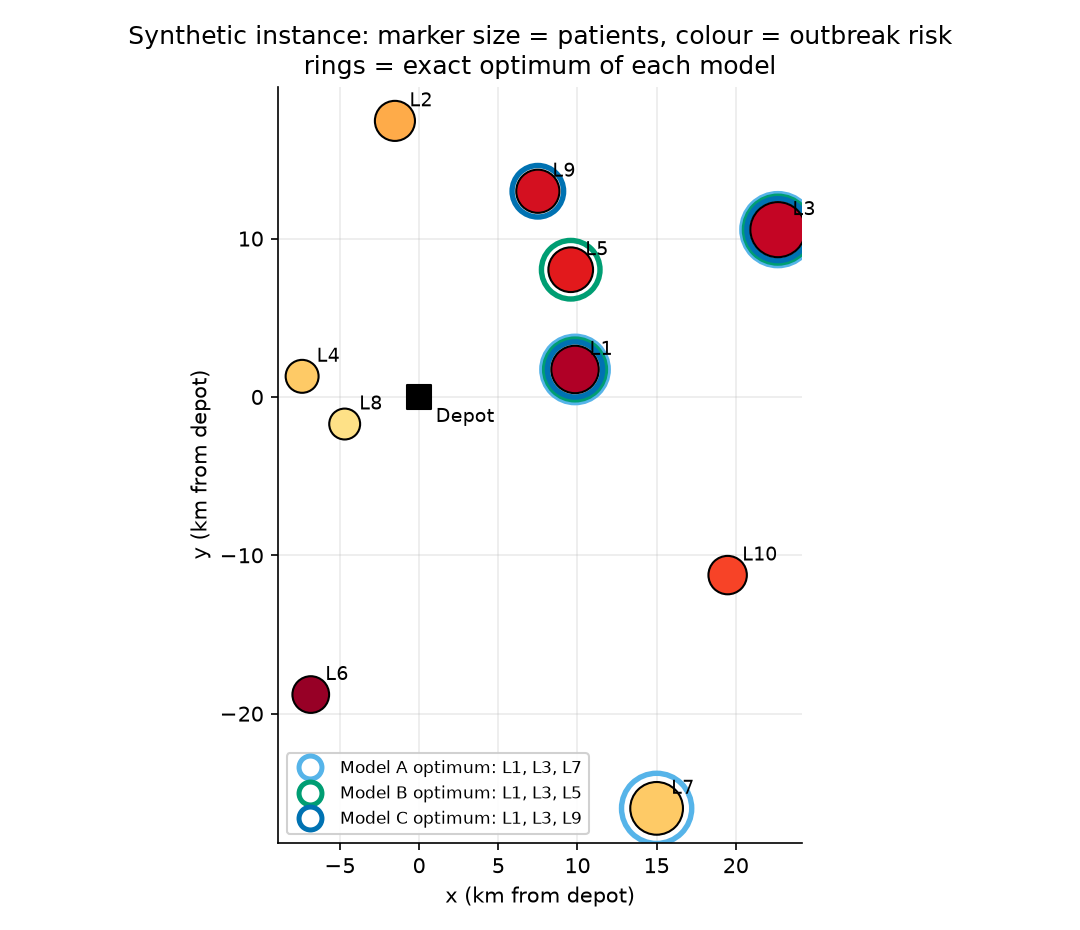

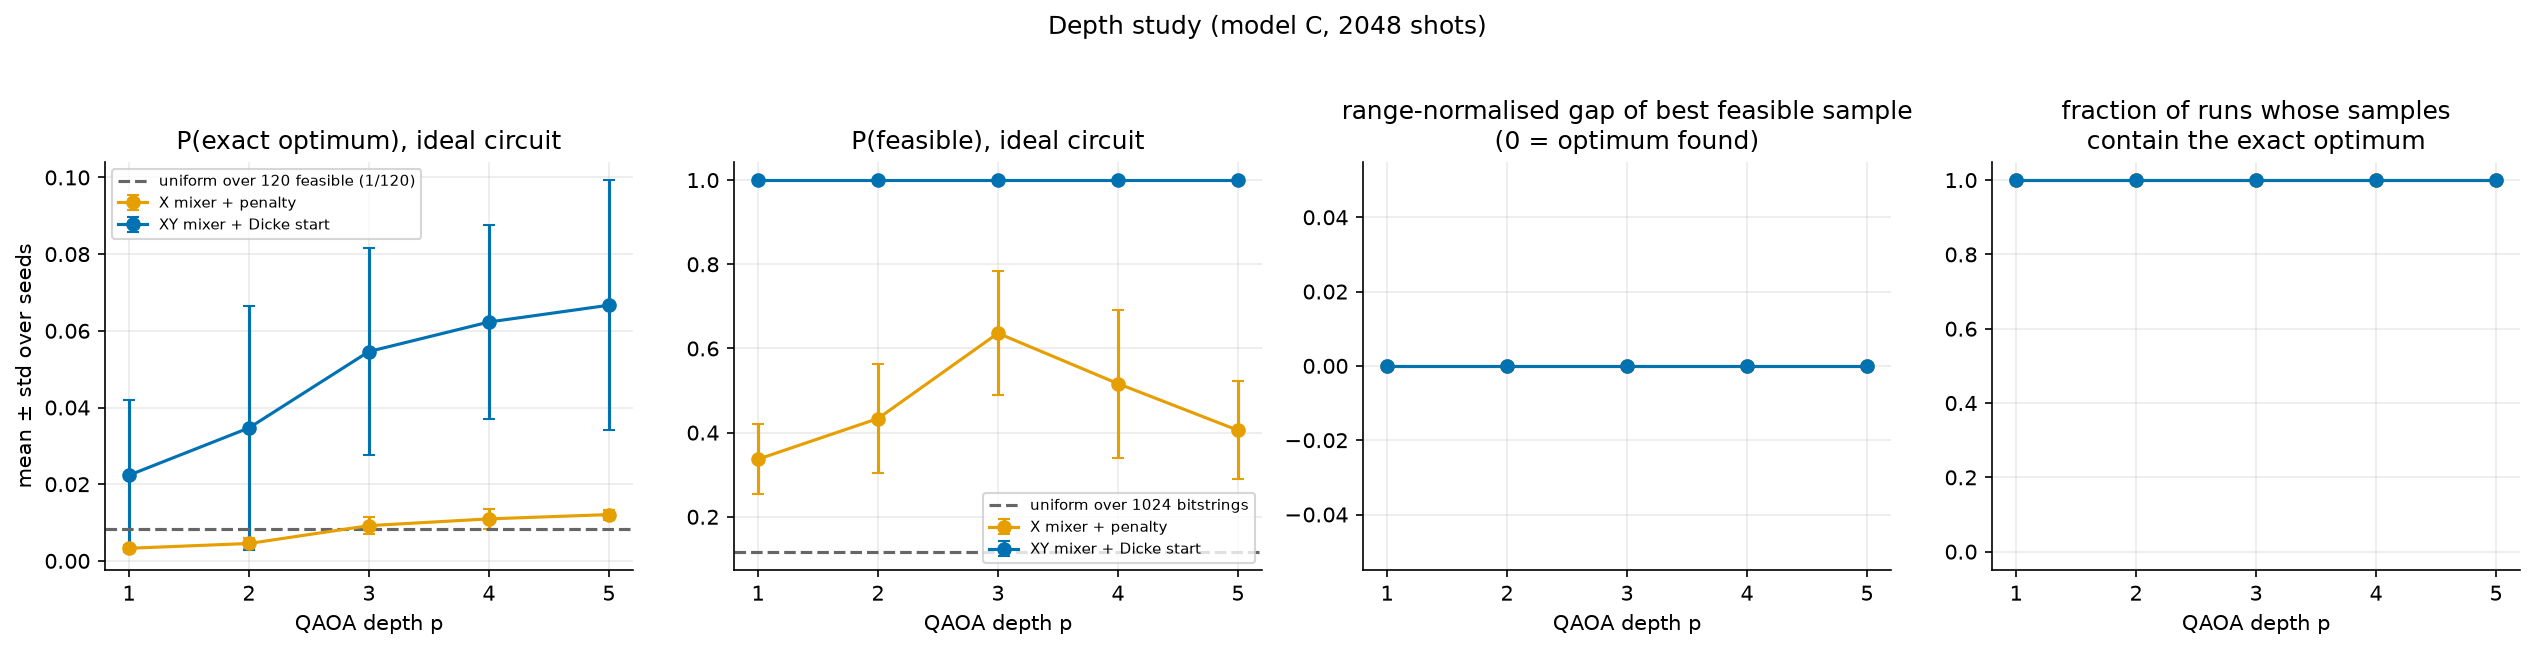

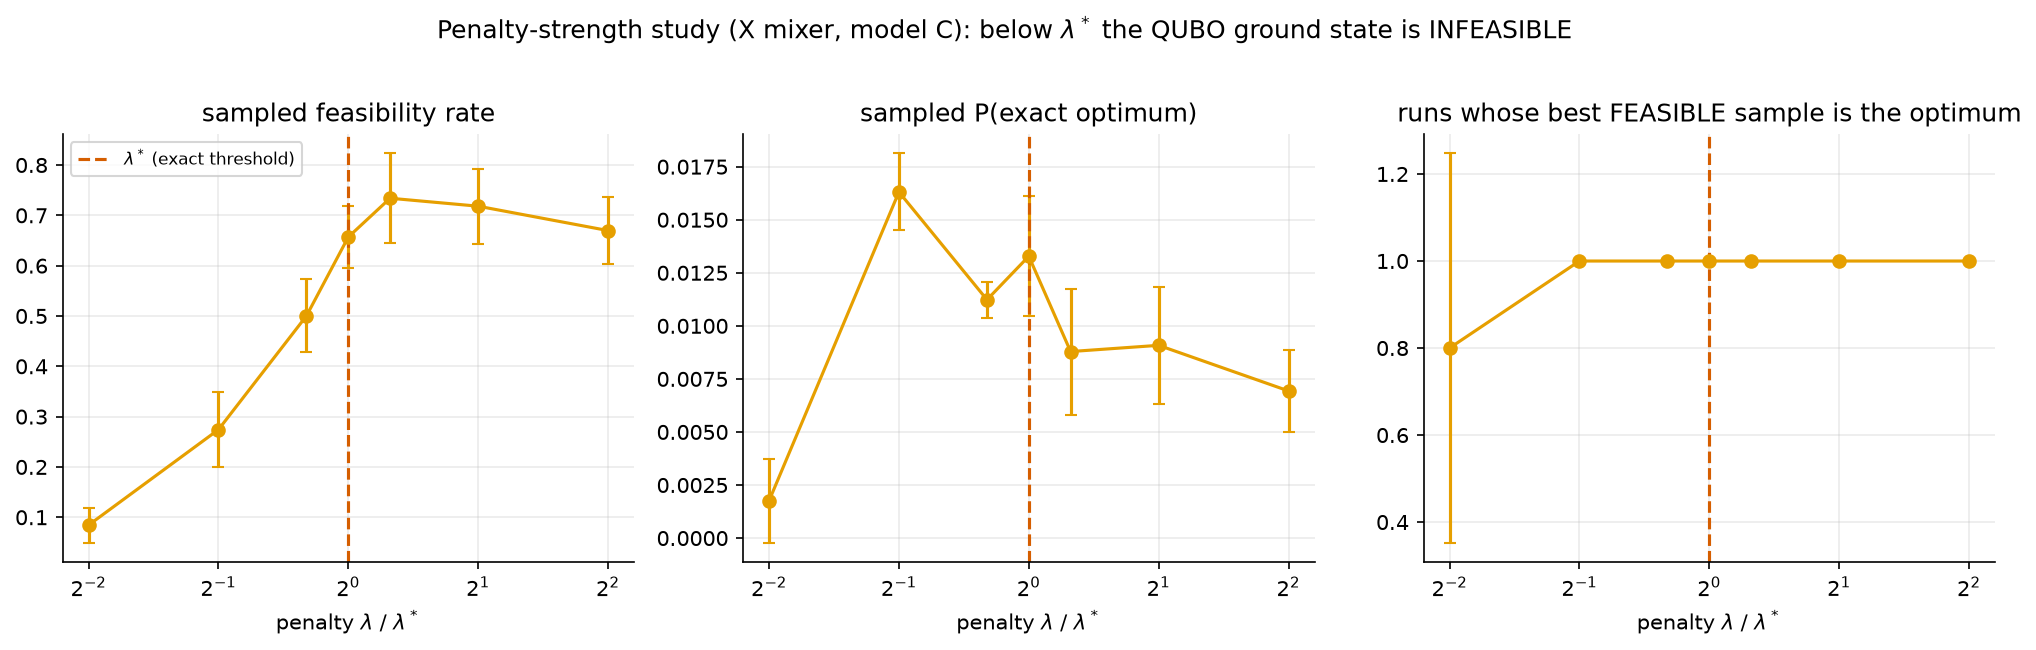

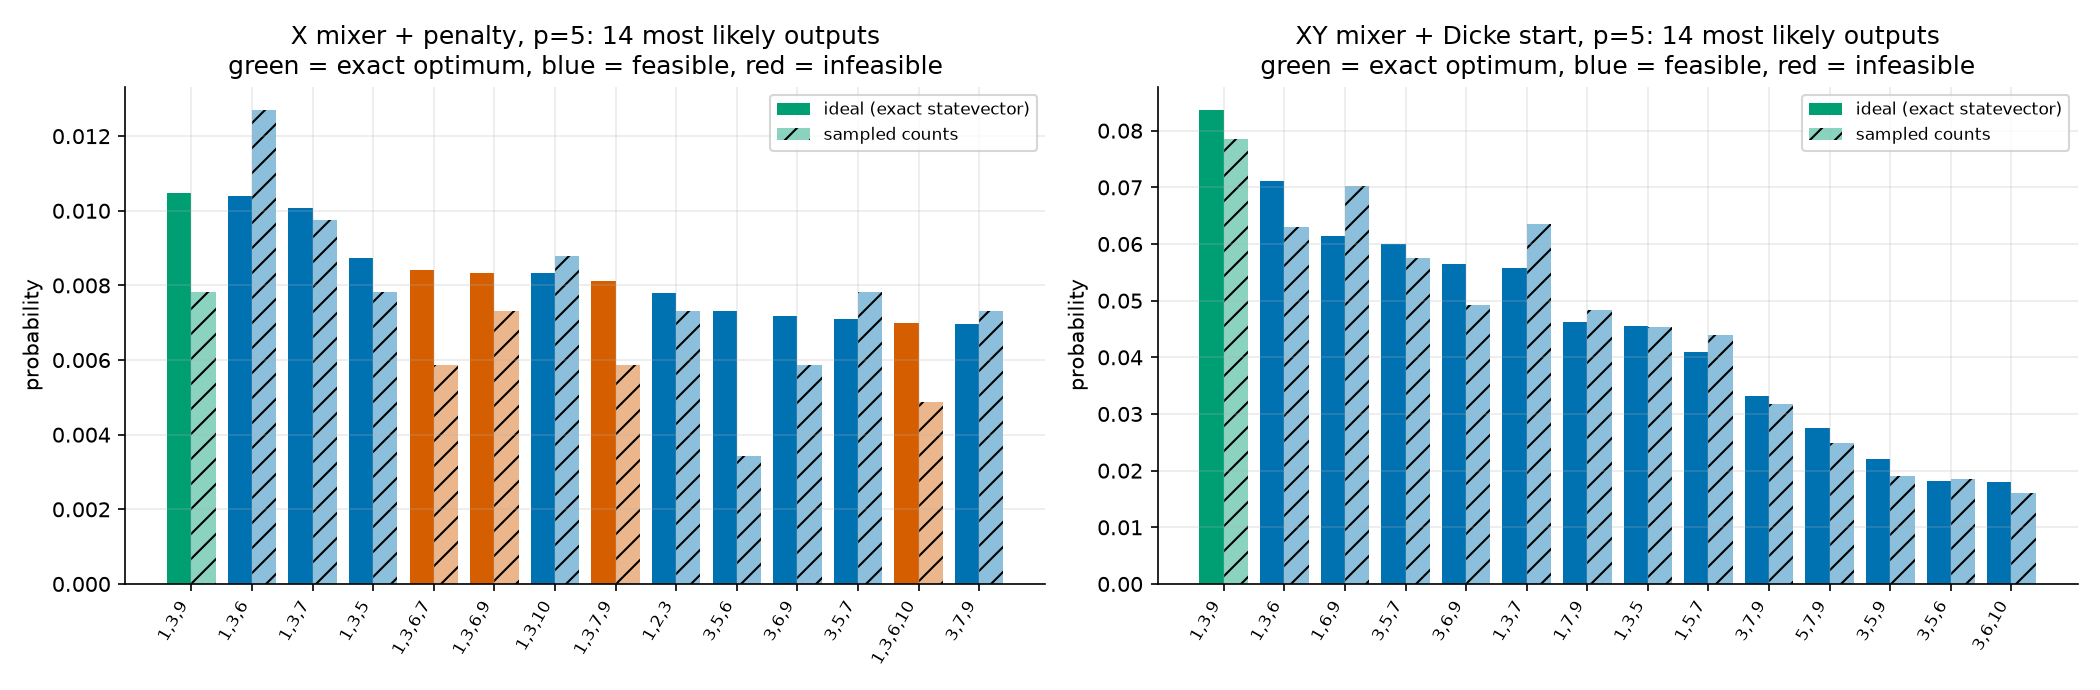

In [9]:
res_dir = ROOT / "experiments" / "results"
from IPython.display import Image, display, Markdown
for f in ["summary_depth.csv", "summary_models_qaoa.csv"]:
    p = res_dir / f
    if p.exists():
        display(Markdown(f"**{f}**")); display(pd.read_csv(p).iloc[:, :8])
for f in ["fig1_instance_and_optima.png", "fig4_depth_study.png", "fig6_penalty_study.png", "fig8_output_distribution.png"]:
    if (res_dir / f).exists():
        display(Image(filename=str(res_dir / f)))

## 10. Limitations (honest summary)
* 10 qubits are classically trivial (120 candidates); **no quantum advantage is claimed or shown**.
* Data are synthetic; weights are modelling choices; one depot, interchangeable teams, no routing.
* Models A and B are linear (optimum = top-3 scores). Model C adds a genuine quadratic term; this extension is ours and its parameters ($w_O$, 15 km reference) are assumptions.
* QAOA with the X mixer + penalty often samples infeasible states; the XY mixer fixes feasibility but costs a deeper circuit (Dicke state preparation by amplitude loading).
* Results are noiseless-simulator results with a local optimiser; hardware noise was not studied.